In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Carga directa del dataset oficial de la NASA (>45,000 registros)
dataframe_raw = pd.read_csv('meteorite_landings.csv')
print('Dimensiones originales del dataset de la NASA:', dataframe_raw.shape)

Dimensiones originales del dataset de la NASA: (45716, 10)


In [2]:
dataframe_raw.head(10)

,name,id,nametype,recclass,mass (g),fall,year,reclat,reclong,GeoLocation
0,Aachen,1,Valid,L5,21.0,Fell,1880.0,50.77500,6.08333,"(50.775, 6.08333)"
1,Aarhus,2,Valid,H6,720.0,Fell,1951.0,56.18333,10.23333,"(56.18333, 10.23333)"
2,Abee,6,Valid,EH4,107000.0,Fell,1952.0,54.21667,-113.00000,"(54.21667, -113.0)"
3,Acapulco,10,Valid,Acapulcoite,1914.0,Fell,1976.0,16.88333,-99.90000,"(16.88333, -99.9)"
4,Achiras,370,Valid,L6,780.0,Fell,1902.0,-33.16667,-64.95000,"(-33.16667, -64.95)"
5,Adhi Kot,379,Valid,EH4,4239.0,Fell,1919.0,32.10000,71.80000,"(32.1, 71.8)"
6,Adzhi-Bogdo (stone),390,Valid,LL3-6,910.0,Fell,1949.0,44.83333,95.16667,"(44.83333, 95.16667)"
7,Agen,392,Valid,H5,30000.0,Fell,1814.0,44.21667,0.61667,"(44.21667, 0.61667)"
8,Aguada,398,Valid,L6,1620.0,Fell,1930.0,-31.60000,-65.23333,"(-31.6, -65.23333)"
9,Aguila Blanca,417,Valid,L,1440.0,Fell,1920.0,-30.86667,-64.55000,"(-30.86667, -64.55)"


In [3]:
# 2. Limpieza de registros incompletos y coordenadas inválidas
df_clean = dataframe_raw.dropna(subset=['mass (g)', 'year', 'reclat', 'reclong']).copy()
df_clean = df_clean[(df_clean['reclat'] != 0) | (df_clean['reclong'] != 0)]
df_clean = df_clean[(df_clean['year'] >= 800) & (df_clean['year'] <= 2026)]

# 3. Mapeo taxonómico de composiciones elementales más abundantes:
# 0 = Basáltico / Acondrita
# 1 = Carbonáceo (Carbono, Volátiles)
# 2 = Metálico (Hierro, Níquel, Oro, Platino)
# 3 = Silicatos / Rocoso (Mg-Fe)
def clasificar_composicion(recclass):
    r = str(recclass).strip()
    if any(ach in r for ach in ['Eucrite', 'Diogenite', 'Howardite', 'Ureilite', 'Aubrite', 'Martian', 'Lunar', 'Achondrite']):
        return 0
    elif r.startswith(('C', 'CM', 'CO', 'CV', 'CI', 'CR', 'CK', 'CH', 'CB')) and not r.startswith('Chondrite-fusion'):
        return 1
    elif 'Iron' in r or 'Pallasite' in r or 'Mesosiderite' in r:
        return 2
    elif r.startswith(('H', 'L', 'LL', 'EH', 'EL', 'R')):
        return 3
    return np.nan

df_clean['Resultado'] = df_clean['recclass'].apply(clasificar_composicion)
df_clean = df_clean.dropna(subset=['Resultado']).copy()
df_clean['Resultado'] = df_clean['Resultado'].astype(int)
clasificadores = ['Basáltico', 'Carbonáceo', 'Metálico', 'Silicatos']
print('Total registros limpios y clasificados:', len(df_clean))
print(df_clean['Resultado'].value_counts())

Total registros limpios y clasificados: 31531
Resultado
3    28616
2     1113
0      970
1      832
Name: count, dtype: int64


In [4]:
# 4. Balanceo estratificado de clases (800 por clase) para aprendizaje equitativo de KNN
df_bal = df_clean.groupby('Resultado').sample(n=800, random_state=42)

dataframe = pd.DataFrame({
    'Masa': np.round(np.log10(df_bal['mass (g)'] + 1), 2),
    'Caida': (df_bal['fall'] == 'Fell').astype(int),
    'Anio': df_bal['year'].astype(int),
    'Latitud': np.round(df_bal['reclat'], 2),
    'Longitud': np.round(df_bal['reclong'], 2),
    'Resultado': df_bal['Resultado']
})

dataframe.groupby('Resultado').size()

,0
Resultado,
0,800
1,800
2,800
3,800


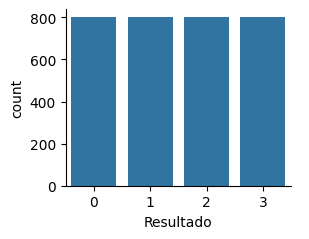

In [5]:
import seaborn as sb
sb.catplot(x='Resultado', data=dataframe, kind="count", height=2.5, aspect=1.2)

In [6]:
Y = dataframe['Resultado']
X = dataframe.drop('Resultado', axis=1)

              precision    recall  f1-score   support

   Basáltico       0.40      0.49      0.44       204
  Carbonáceo       0.47      0.43      0.45       260
    Metálico       0.74      0.72      0.73       248
   Silicatos       0.45      0.42      0.43       248

    accuracy                           0.51       960
   macro avg       0.52      0.51      0.51       960
weighted avg       0.52      0.51      0.52       960


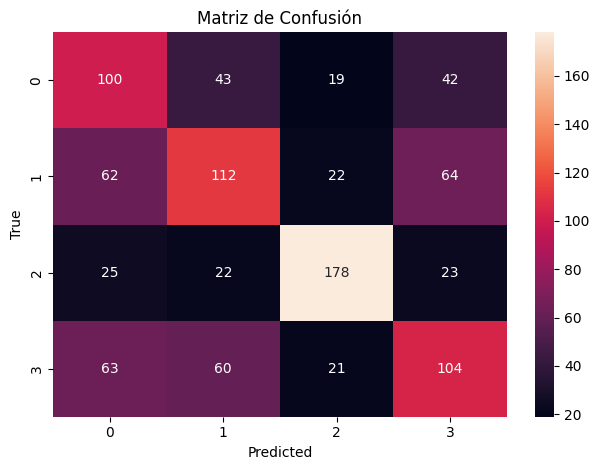

In [7]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=30)

from sklearn.neighbors import KNeighborsClassifier
knn_mm = KNeighborsClassifier(n_neighbors=1)
knn_mm.fit(X_train, Y_train)

predicciones = knn_mm.predict(X_test)

from sklearn.metrics import classification_report, confusion_matrix
sns.heatmap(confusion_matrix(Y_test, predicciones), annot=True, fmt='d')
plt.title('Matriz de Confusión')
plt.xlabel('Predicted')
plt.ylabel('True')
print(classification_report(Y_test, predicciones, target_names=clasificadores))

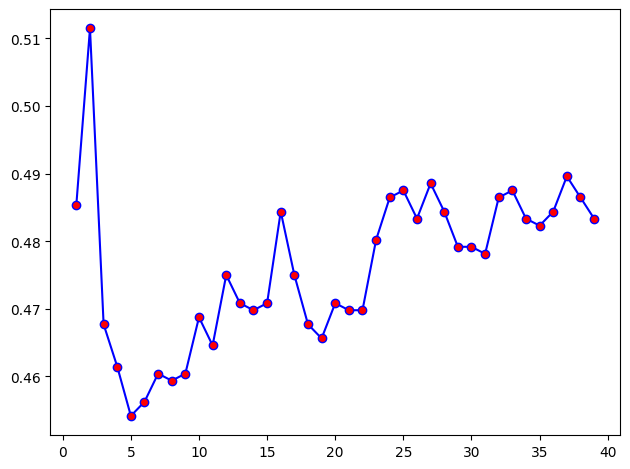

In [8]:
tasa_error = []
for i in range(1, 40):
    knn = KNeighborsClassifier(n_neighbors=i)
    knn.fit(X_train, Y_train)
    predicciones_i = knn.predict(X_test)
    tasa_error.append(np.mean(predicciones_i != Y_test))

valores = range(1, 40)
plt.plot(valores, tasa_error, color='blue', marker='o', markerfacecolor='red')

              precision    recall  f1-score   support

   Basáltico       0.39      0.59      0.47       204
  Carbonáceo       0.55      0.50      0.53       260
    Metálico       0.76      0.75      0.76       248
   Silicatos       0.51      0.35      0.41       248

    accuracy                           0.55       960
   macro avg       0.55      0.55      0.54       960
weighted avg       0.56      0.55      0.54       960


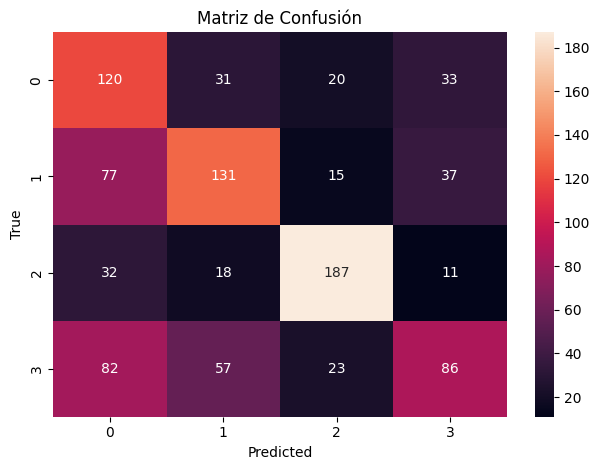

In [9]:
from sklearn.neighbors import KNeighborsClassifier
knn_mm = KNeighborsClassifier(n_neighbors=5)
knn_mm.fit(X_train, Y_train)

predicciones = knn_mm.predict(X_test)

from sklearn.metrics import classification_report, confusion_matrix
sns.heatmap(confusion_matrix(Y_test, predicciones), annot=True, fmt='d')
plt.title('Matriz de Confusión')
plt.xlabel('Predicted')
plt.ylabel('True')
print(classification_report(Y_test, predicciones, target_names=clasificadores))

In [10]:
# Inferencia con nuevo caso: [Masa=4.73, Caida=1, Anio=1880, Latitud=35.33, Longitud=51.63]
print(knn_mm.predict([[4.73, 1, 1880, 35.33, 51.63]]))
print(knn_mm.predict_proba([[4.73, 1, 1880, 35.33, 51.63]]))

[0]
[[0.4 0.2 0.4 0. ]]
